In [1]:
from pathlib import Path
import os
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

# Locate the project folder
PROJECT_DIR = Path.cwd()

while not (PROJECT_DIR / ".env").exists():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("Could not locate the project .env file")
    PROJECT_DIR = PROJECT_DIR.parent

# Load database credentials
load_dotenv(PROJECT_DIR / ".env")

# Create PostgreSQL connection
database_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PG_USER"),
    password=os.getenv("PG_PASSWORD"),
    host=os.getenv("PG_HOST"),
    port=int(os.getenv("PG_PORT")),
    database=os.getenv("PG_DATABASE")
)

engine = create_engine(database_url)

with engine.connect() as connection:
    print("PostgreSQL connection successful!")
    print(connection.exec_driver_sql("SELECT version();").scalar())

PostgreSQL connection successful!
PostgreSQL 18.4 on x86_64-windows, compiled by msvc-19.44.35227, 64-bit


Read the Data

In [2]:
query = """
SELECT
    complaint_id,
    product,
    issue,
    company,
    complaint_date,
    complaint_text,
    company_response,
    company_public_response
FROM complaints
ORDER BY complaint_date, complaint_id;
"""

df = pd.read_sql(query, engine)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (5004, 8)


In [3]:
display(df.drop(columns=["complaint_text"]).head())

,complaint_id,product,issue,company,complaint_date,company_response,company_public_response
0,22763705,Mortgage,Trouble during payment process,WELLS FARGO & COMPANY,2026-06-01,Closed with explanation,Company has responded to the consumer and the ...
1,22764058,Debt collection,Took or threatened to take negative or legal a...,"Shellpoint Partners, LLC",2026-06-01,Closed with explanation,Company has responded to the consumer and the ...
2,22764973,Debt collection,Attempts to collect debt not owed,"Revenue Systems, Inc.",2026-06-01,Closed with explanation,Company believes it acted appropriately as aut...
3,22766264,Mortgage,Trouble during payment process,"Shellpoint Partners, LLC",2026-06-01,Closed with explanation,Company believes it acted appropriately as aut...
4,22767736,Vehicle loan or lease,Problem with a company's investigation into an...,AMERICAN HONDA FINANCE CORP,2026-06-01,Closed with explanation,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5004 entries, 0 to 5003
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   complaint_id             5004 non-null   int64 
 1   product                  5001 non-null   str   
 2   issue                    5001 non-null   str   
 3   company                  5001 non-null   str   
 4   complaint_date           5004 non-null   object
 5   complaint_text           5004 non-null   str   
 6   company_response         5001 non-null   str   
 7   company_public_response  1667 non-null   str   
dtypes: int64(1), object(1), str(6)
memory usage: 7.7+ MB


In [5]:
df["text_length"] = df["complaint_text"].str.len()

df["text_length"].describe()

count     5004.000000
mean      1415.386291
std       1414.205734
min         47.000000
25%        533.000000
50%       1074.000000
75%       1854.250000
max      30199.000000
Name: text_length, dtype: float64

preparing date and text length data 

In [6]:
# Convert complaint_date to datetime
df["complaint_date"] = pd.to_datetime(df["complaint_date"])

# Calculate complaint narrative length
df["text_length"] = df["complaint_text"].str.len()

# Calculate word count
df["word_count"] = df["complaint_text"].str.split().str.len()

print("Date range:")
print(df["complaint_date"].min(), "to", df["complaint_date"].max())

print("\nAverage word count:")
print(round(df["word_count"].mean(), 2))

print("\nUpdated data types:")
print(df.dtypes)

Date range:
2026-06-01 00:00:00 to 2026-11-08 00:00:00

Average word count:
235.4

Updated data types:
complaint_id                       int64
product                              str
issue                                str
company                              str
complaint_date             datetime64[s]
complaint_text                       str
company_response                     str
company_public_response              str
text_length                        int64
word_count                         int64
dtype: object


Product Distribution

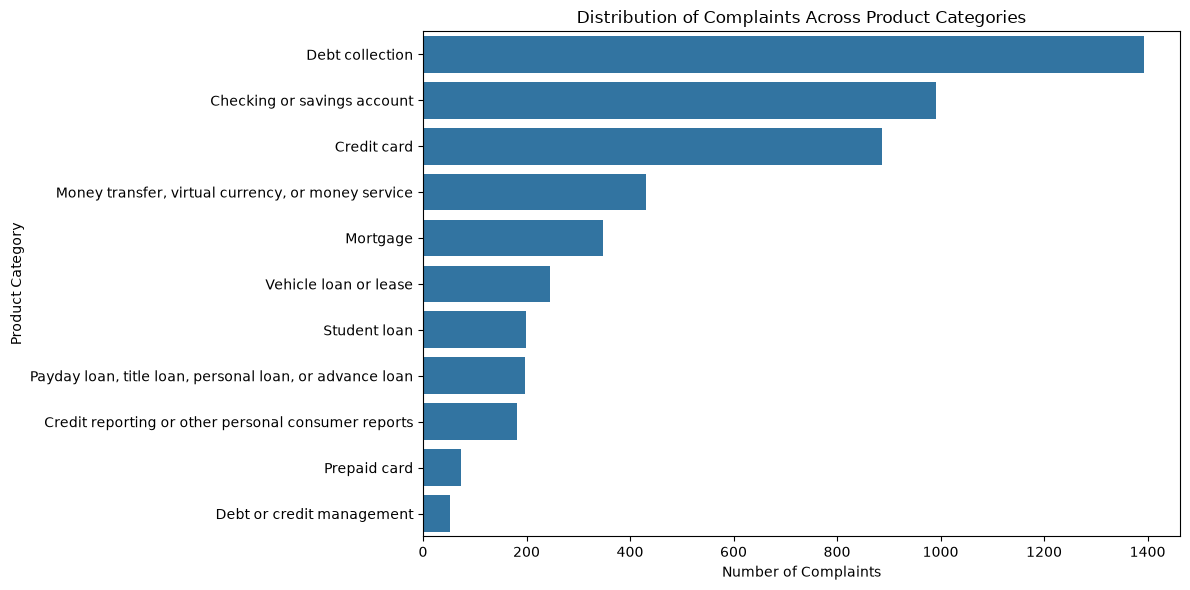

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

product_counts = df["product"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.title("Distribution of Complaints Across Product Categories")
plt.xlabel("Number of Complaints")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

Complaint trends over time

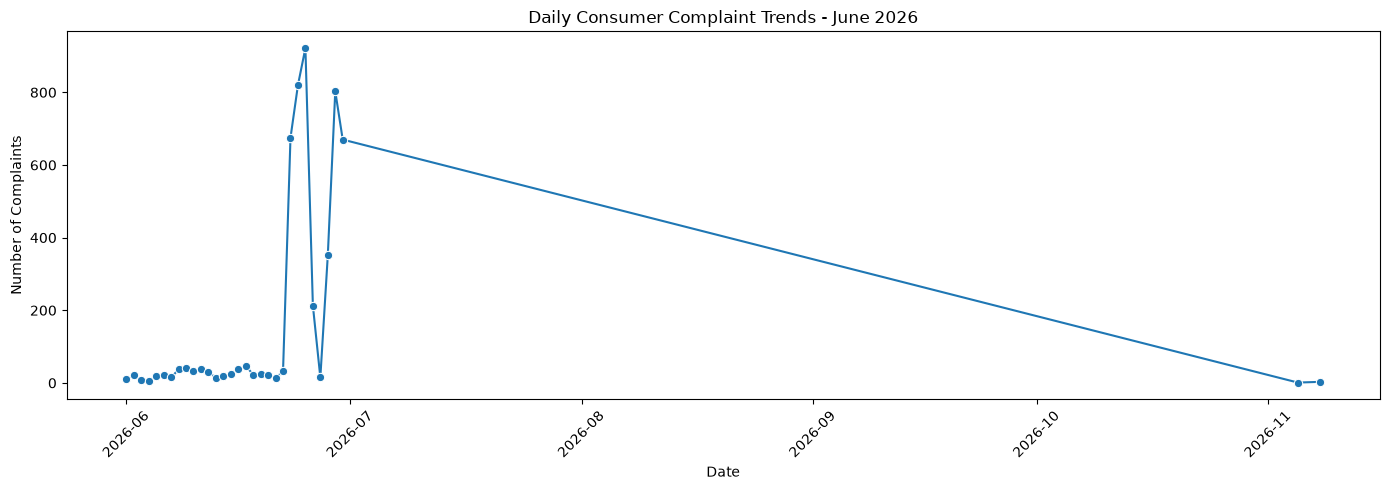

In [8]:
# Daily complaint count
daily_complaints = (
    df.groupby("complaint_date")
    .size()
    .reset_index(name="complaint_count")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_complaints,
    x="complaint_date",
    y="complaint_count",
    marker="o"
)

plt.title("Daily Consumer Complaint Trends - June 2026")
plt.xlabel("Date")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

complaint narrative length distribution

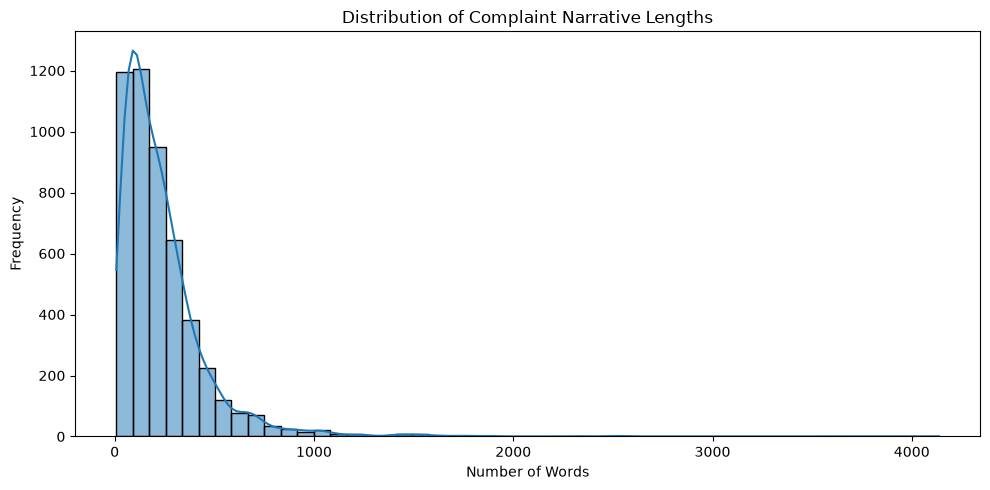

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Complaint Narrative Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Text Preprocessing

In [10]:
import re

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Replace email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " EMAIL ",
        text
    )

    # Replace phone numbers
    text = re.sub(
        r"\b(?:\+?\d[\d\s().-]{7,}\d)\b",
        " PHONE ",
        text
    )

    # Replace redaction placeholders such as XXXX
    text = re.sub(r"\bx{2,}\b", " ", text)

    # Keep letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [11]:
df["cleaned_text"] = df["complaint_text"].apply(clean_text)

In [12]:
print("Original average length:",
      df["complaint_text"].str.len().mean())

print("Cleaned average length:",
      df["cleaned_text"].str.len().mean())

print("Empty cleaned records:",
      (df["cleaned_text"].str.strip() == "").sum())

Original average length: 1415.3862909672262
Cleaned average length: 1312.9782174260592
Empty cleaned records: 0


validate cleaned dataset

In [13]:
# Check missing values
print("Missing cleaned text:",
      df["cleaned_text"].isna().sum())

# Check empty text
print("Empty cleaned text:",
      (df["cleaned_text"].str.strip() == "").sum())

# Check missing target labels
print("Missing product labels:",
      df["product"].isna().sum())

# Check duplicate complaint IDs
print("Duplicate complaint IDs:",
      df["complaint_id"].duplicated().sum())

# Check product distribution
print("\nProduct distribution:")
print(df["product"].value_counts())

Missing cleaned text: 0
Empty cleaned text: 0
Missing product labels: 3
Duplicate complaint IDs: 0

Product distribution:
product
Debt collection                                            1393
Checking or savings account                                 992
Credit card                                                 887
Money transfer, virtual currency, or money service          430
Mortgage                                                    348
Vehicle loan or lease                                       246
Student loan                                                199
Payday loan, title loan, personal loan, or advance loan     198
Credit reporting or other personal consumer reports         182
Prepaid card                                                 73
Debt or credit management                                    53
Name: count, dtype: int64


checking for very short complaints

In [14]:
short_complaints = df[df["cleaned_text"].str.split().str.len() < 10]

print("Complaints with fewer than 10 words:",
      len(short_complaints))

print("Percentage:",
      round(len(short_complaints) / len(df) * 100, 2), "%")

Complaints with fewer than 10 words: 12
Percentage: 0.24 %


MODEL PREPARATION AND TRAINING

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

defining features and target

In [16]:
X = df["cleaned_text"]
y = df["product"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Number of categories:", y.nunique())

Features: (5004,)
Target: (5004,)
Number of categories: 11


splitting dataset into training and testing

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining category distribution:")
print(y_train.value_counts())

ValueError: Input contains NaN

verifying the split

In [ ]:
print("Training proportions:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting proportions:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training proportions:
product
Debt collection                                            27.88
Checking or savings account                                19.82
Credit card                                                17.75
Money transfer, virtual currency, or money service          8.60
Mortgage                                                    6.95
Vehicle loan or lease                                       4.92
Student loan                                                3.98
Payday loan, title loan, personal loan, or advance loan     3.95
Credit reporting or other personal consumer reports         3.65
Prepaid card                                                1.45
Debt or credit management                                   1.05
Name: proportion, dtype: float64

Testing proportions:
product
Debt collection                                            27.8
Checking or savings account                                19.8
Credit card                                                17.7


TF-IDF AND LOGISTIC REGRESSION

building the pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Model pipeline created successfully!")

Model pipeline created successfully!


model training

In [ ]:
print("Training model...")

model.fit(X_train, y_train)

print("Model training completed!")

Training model...
Model training completed!


predictions

In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))

Predictions generated successfully!
Total predictions: 1000


MODEL EVALUATION

evaluation metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}")

MODEL EVALUATION RESULTS
------------------------
Accuracy:  0.7950
Precision: 0.8079
Recall:    0.7950
Weighted F1-score: 0.7959


evaluating individual categories

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

                                                         precision    recall  f1-score   support

                            Checking or savings account       0.74      0.81      0.77       198
                                            Credit card       0.78      0.84      0.81       177
    Credit reporting or other personal consumer reports       0.61      0.86      0.71        36
                                        Debt collection       0.94      0.83      0.88       278
                              Debt or credit management       1.00      0.27      0.43        11
     Money transfer, virtual currency, or money service       0.72      0.67      0.69        86
                                               Mortgage       0.93      0.89      0.91        70
Payday loan, title loan, personal loan, or advance loan       0.44      0.55      0.49        40
                                           Prepaid card       0.33      0.20      0.25        15
                             

macro F1 score

In [ ]:
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Macro F1-score: {macro_f1:.4f}")

Macro F1-score: 0.6999


Visualizing the confusion matrix

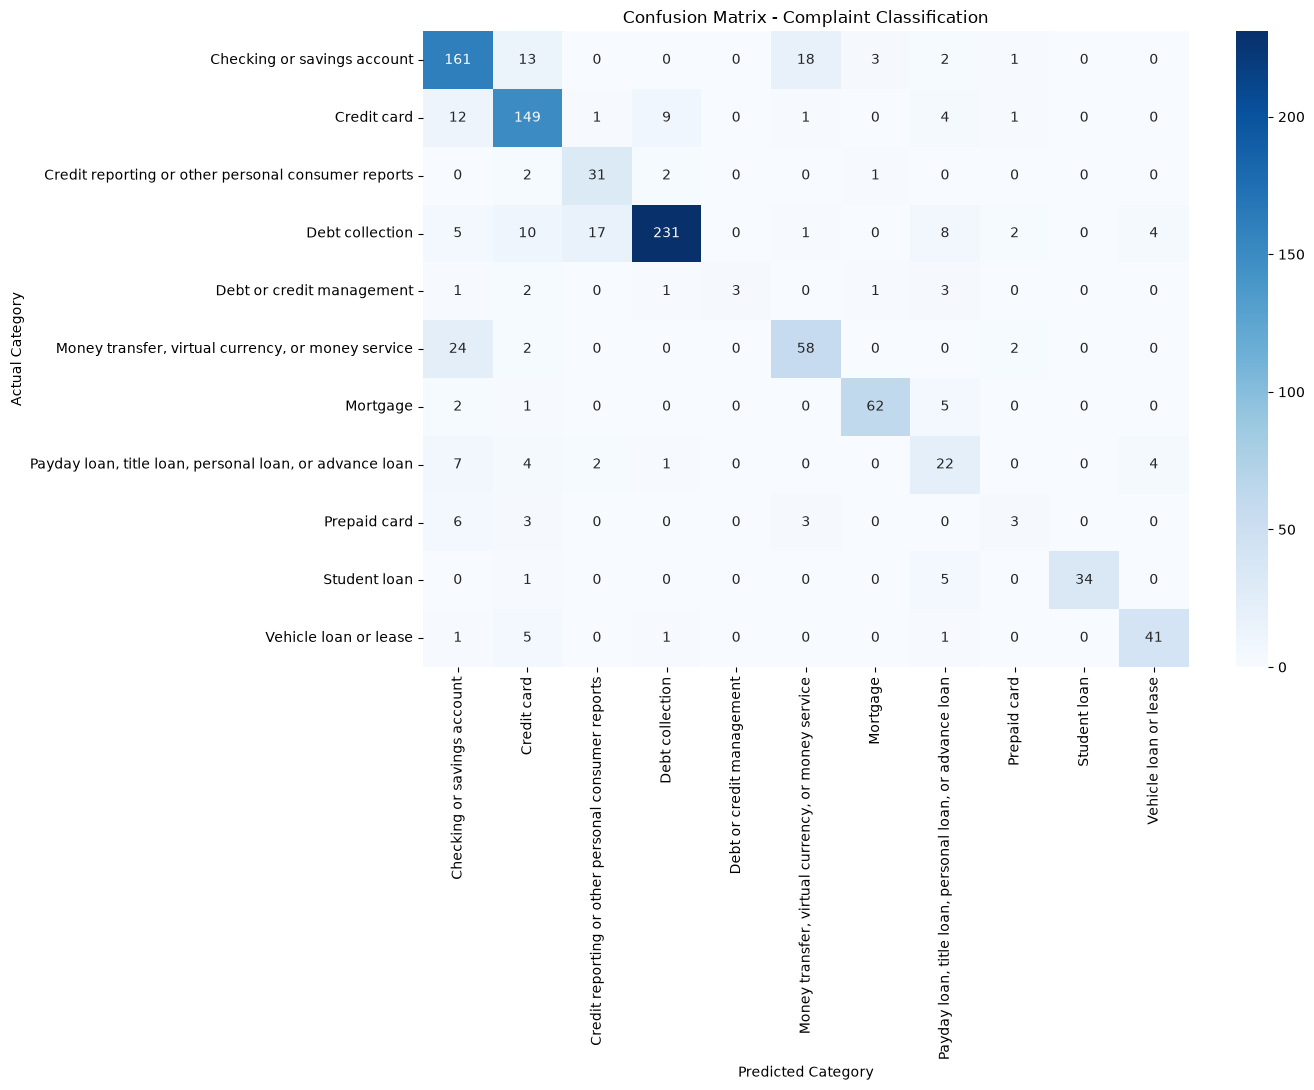

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Complaint Classification")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Investigating incorrect predictions

In [ ]:
# Identify incorrectly classified complaints
misclassified = df.loc[X_test.index].copy()

misclassified["actual_category"] = y_test
misclassified["predicted_category"] = y_pred

misclassified = misclassified[
    misclassified["actual_category"] !=
    misclassified["predicted_category"]
]

# Count the most common classification errors
error_summary = (
    misclassified
    .groupby(["actual_category", "predicted_category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

error_summary.head(15)

,actual_category,predicted_category,count
26,"Money transfer, virtual currency, or money ser...",Checking or savings account,24
1,Checking or savings account,"Money transfer, virtual currency, or money ser...",18
16,Debt collection,Credit reporting or other personal consumer re...,17
0,Checking or savings account,Credit card,13
5,Credit card,Checking or savings account,12
15,Debt collection,Credit card,10
7,Credit card,Debt collection,9
18,Debt collection,"Payday loan, title loan, personal loan, or adv...",8
32,"Payday loan, title loan, personal loan, or adv...",Checking or savings account,7
37,Prepaid card,Checking or savings account,6


investigating issue categories behind the error

In [ ]:
# Focus on the two largest groups of classification errors

focus_errors = misclassified[
    (
        (misclassified["actual_category"] ==
         "Money transfer, virtual currency, or money service") &
        (misclassified["predicted_category"] ==
         "Checking or savings account")
    )
    |
    (
        (misclassified["actual_category"] ==
         "Checking or savings account") &
        (misclassified["predicted_category"] ==
         "Money transfer, virtual currency, or money service")
    )
]

issue_analysis = (
    focus_errors
    .groupby(
        ["actual_category", "predicted_category", "issue"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

issue_analysis

,actual_category,predicted_category,issue,count
1,Checking or savings account,"Money transfer, virtual currency, or money ser...",Managing an account,11
3,"Money transfer, virtual currency, or money ser...",Checking or savings account,Fraud or scam,11
2,Checking or savings account,"Money transfer, virtual currency, or money ser...",Problem with a lender or other company chargin...,4
9,"Money transfer, virtual currency, or money ser...",Checking or savings account,Unauthorized transactions or other transaction...,4
0,Checking or savings account,"Money transfer, virtual currency, or money ser...",Closing an account,3
6,"Money transfer, virtual currency, or money ser...",Checking or savings account,Other transaction problem,3
10,"Money transfer, virtual currency, or money ser...",Checking or savings account,Wrong amount charged or received,2
5,"Money transfer, virtual currency, or money ser...",Checking or savings account,Money was not available when promised,1
4,"Money transfer, virtual currency, or money ser...",Checking or savings account,"Managing, opening, or closing your mobile wall...",1
8,"Money transfer, virtual currency, or money ser...",Checking or savings account,Trouble accessing funds in your mobile or digi...,1


Compare clas-weighting strategies

In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report

# Create a second model without class weighting
model_unweighted = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train and predict
model_unweighted.fit(X_train, y_train)
y_pred_unweighted = model_unweighted.predict(X_test)

# Evaluate
print(classification_report(
    y_test,
    y_pred_unweighted,
    zero_division=0
))

                                                         precision    recall  f1-score   support

                            Checking or savings account       0.64      0.90      0.75       198
                                            Credit card       0.71      0.85      0.78       177
    Credit reporting or other personal consumer reports       0.94      0.44      0.60        36
                                        Debt collection       0.80      0.96      0.87       278
                              Debt or credit management       1.00      0.09      0.17        11
     Money transfer, virtual currency, or money service       0.80      0.38      0.52        86
                                               Mortgage       0.92      0.83      0.87        70
Payday loan, title loan, personal loan, or advance loan       0.67      0.05      0.09        40
                                           Prepaid card       0.00      0.00      0.00        15
                             

testing regularization strength

In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training records:", len(X_train_new))
print("Validation records:", len(X_val))

Training records: 3200
Validation records: 800


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

c_values = [0.1, 1.0, 10.0]

results = []

for c in c_values:

    model_c = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            C=c,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model_c.fit(X_train_new, y_train_new)

    val_pred = model_c.predict(X_val)

    results.append({
        "C": c,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro Precision": precision_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, val_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,C,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,0.1,0.7338,0.6488,0.6873,0.6420,0.7434
1,1.0,0.7962,0.8136,0.6828,0.6964,0.7927
2,10.0,0.8050,0.8556,0.6606,0.6917,0.7982


evaluation of selected configuration on test set: c=1.0

In [ ]:
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on the complete training set
final_model.fit(X_train, y_train)

# Predict on the untouched test set
final_predictions = final_model.predict(X_test)

# Evaluate
print("Final Model Evaluation")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, final_predictions))

print("Macro F1:", f1_score(
    y_test, final_predictions, average="macro"
))

print("Weighted F1:", f1_score(
    y_test, final_predictions, average="weighted"
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

Final Model Evaluation
----------------------
Accuracy: 0.795
Macro F1: 0.6998739460685578
Weighted F1: 0.7959366631945246

Classification Report:
                                                         precision    recall  f1-score   support

                            Checking or savings account       0.74      0.81      0.77       198
                                            Credit card       0.78      0.84      0.81       177
    Credit reporting or other personal consumer reports       0.61      0.86      0.71        36
                                        Debt collection       0.94      0.83      0.88       278
                              Debt or credit management       1.00      0.27      0.43        11
     Money transfer, virtual currency, or money service       0.72      0.67      0.69        86
                                               Mortgage       0.93      0.89      0.91        70
Payday loan, title loan, personal loan, or advance loan       0.44      0.55

training and comparing linear svm and naive bayes

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    ),

    "Complement Naive Bayes": ComplementNB(
        alpha=1.0
    )
}

comparison_results = []

for name, classifier in models.items():

    text_model = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    text_model.fit(X_train_new, y_train_new)

    predictions = text_model.predict(X_val)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions,
            average="weighted",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Linear SVM,0.810,0.8516,0.6784,0.7116,0.8041
1,Complement Naive Bayes,0.695,0.7575,0.4511,0.4784,0.6467


linearsvm performing the best so far, classification report

In [ ]:
# Rebuild Linear SVM with the same configuration

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train_new, y_train_new)

svm_val_predictions = svm_model.predict(X_val)

print("Linear SVM - Validation Classification Report")
print(classification_report(
    y_val,
    svm_val_predictions,
    zero_division=0
))

Linear SVM - Validation Classification Report
                                                         precision    recall  f1-score   support

                            Checking or savings account       0.78      0.81      0.79       159
                                            Credit card       0.77      0.87      0.82       142
    Credit reporting or other personal consumer reports       0.84      0.72      0.78        29
                                        Debt collection       0.88      0.89      0.88       223
                              Debt or credit management       1.00      0.25      0.40         8
     Money transfer, virtual currency, or money service       0.61      0.67      0.64        69
                                               Mortgage       0.93      0.96      0.95        55
Payday loan, title loan, personal loan, or advance loan       0.84      0.50      0.63        32
                                           Prepaid card       1.00      0.17    

tune linear svm

In [ ]:
svm_results = []

for c in [0.1, 1.0, 10.0]:

    svm = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            C=c,
            class_weight="balanced",
            random_state=42
        ))
    ])

    svm.fit(X_train_new, y_train_new)

    predictions = svm.predict(X_val)

    svm_results.append({
        "C": c,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions,
            average="weighted",
            zero_division=0
        )
    })

svm_results_df = pd.DataFrame(svm_results)
svm_results_df.round(4)

,C,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,0.1,0.8125,0.7909,0.6940,0.7049,0.8076
1,1.0,0.8100,0.8516,0.6784,0.7116,0.8041
2,10.0,0.7925,0.8554,0.6401,0.6710,0.7840


compare c=0.1 and 1.0 configurations since both are around same

In [ ]:
for c in [0.1, 1.0]:

    candidate = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            C=c,
            class_weight="balanced",
            random_state=42
        ))
    ])

    candidate.fit(X_train_new, y_train_new)
    predictions = candidate.predict(X_val)

    print(f"\n{'='*65}")
    print(f"LINEAR SVM - C = {c}")
    print('='*65)

    print(classification_report(
        y_val,
        predictions,
        zero_division=0
    ))


LINEAR SVM - C = 0.1
                                                         precision    recall  f1-score   support

                            Checking or savings account       0.77      0.84      0.81       159
                                            Credit card       0.81      0.85      0.83       142
    Credit reporting or other personal consumer reports       0.59      0.79      0.68        29
                                        Debt collection       0.91      0.86      0.88       223
                              Debt or credit management       1.00      0.25      0.40         8
     Money transfer, virtual currency, or money service       0.66      0.65      0.66        69
                                               Mortgage       0.93      1.00      0.96        55
Payday loan, title loan, personal loan, or advance loan       0.70      0.50      0.58        32
                                           Prepaid card       0.67      0.17      0.27        12
       

final testset configuration

In [ ]:
from sklearn.metrics import classification_report

final_candidates = {
    "Logistic Regression": final_model,
    "Linear SVM C=0.1": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            C=0.1,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Linear SVM C=1.0": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

test_results = []

for name, candidate in final_candidates.items():

    if name != "Logistic Regression":
        candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_test)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, predictions,
            average="weighted"
        )
    })

test_comparison = pd.DataFrame(test_results)
test_comparison.round(4)

,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.795,0.6999,0.7959
1,Linear SVM C=0.1,0.812,0.7155,0.8105
2,Linear SVM C=1.0,0.819,0.7283,0.8154


In [ ]:
final_svm = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

final_svm.fit(X_train, y_train)

final_svm_predictions = final_svm.predict(X_test)

print(classification_report(
    y_test,
    final_svm_predictions,
    zero_division=0
))

                                                         precision    recall  f1-score   support

                            Checking or savings account       0.76      0.84      0.80       198
                                            Credit card       0.78      0.85      0.81       177
    Credit reporting or other personal consumer reports       0.73      0.75      0.74        36
                                        Debt collection       0.91      0.91      0.91       278
                              Debt or credit management       1.00      0.36      0.53        11
     Money transfer, virtual currency, or money service       0.74      0.67      0.71        86
                                               Mortgage       0.93      0.89      0.91        70
Payday loan, title loan, personal loan, or advance loan       0.56      0.55      0.56        40
                                           Prepaid card       0.75      0.20      0.32        15
                             

inspect the final confusion matrix

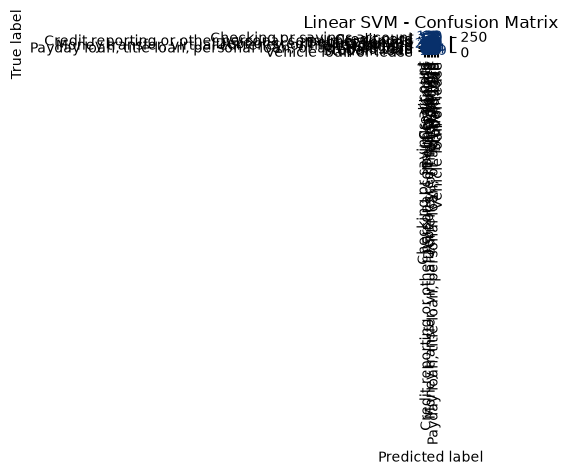

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_svm_predictions,
    xticks_rotation="vertical",
    cmap="Blues",
    values_format="d"
)

plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()

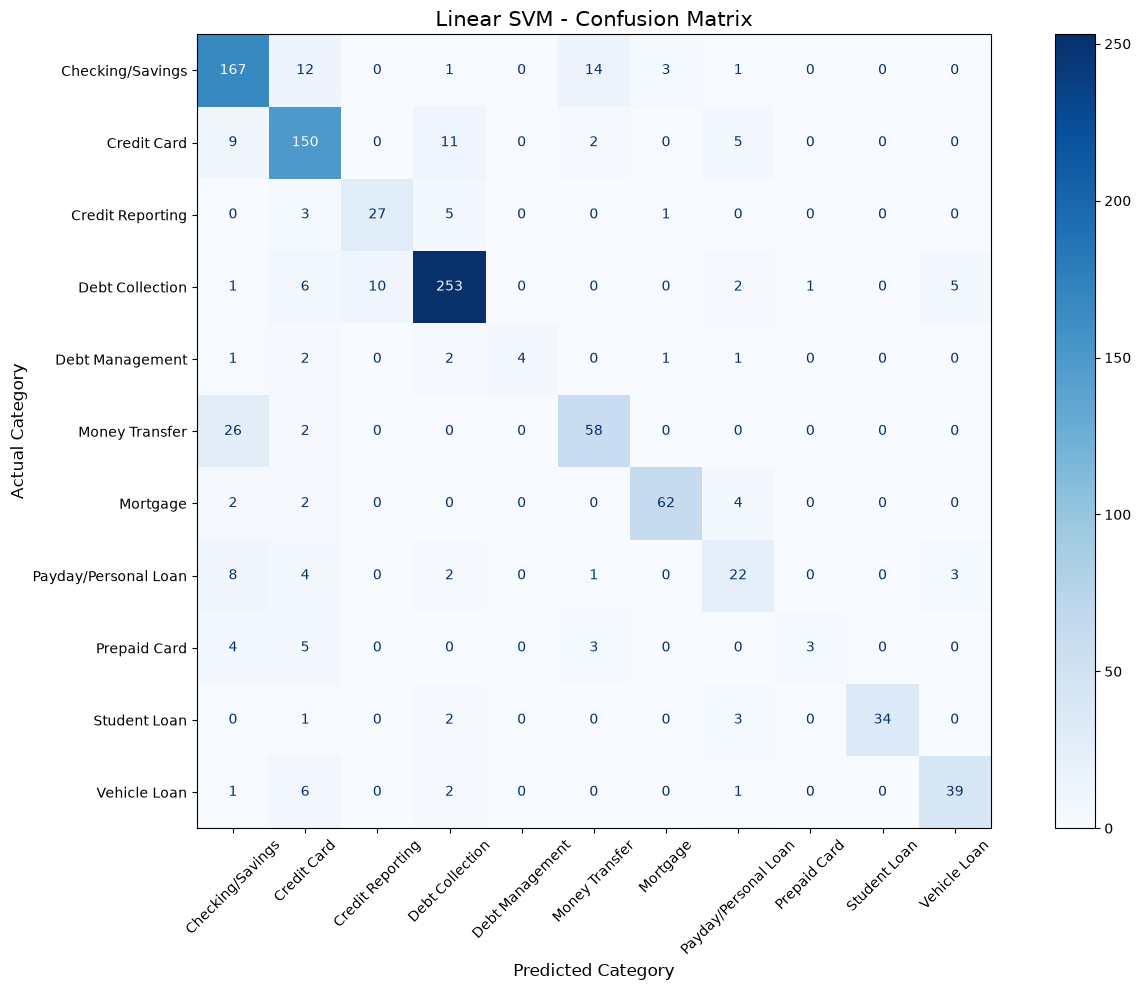

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Short names for better readability
short_labels = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt Management",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

display_labels = [
    short_labels[label] for label in final_svm.classes_
]

fig, ax = plt.subplots(figsize=(14, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_svm_predictions,
    labels=final_svm.classes_,
    display_labels=display_labels,
    xticks_rotation=45,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Linear SVM - Confusion Matrix", fontsize=15)
ax.set_xlabel("Predicted Category", fontsize=12)
ax.set_ylabel("Actual Category", fontsize=12)

plt.tight_layout()
plt.show()

save the trained model

In [ ]:
import joblib
from pathlib import Path

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / "supportlens_svm.joblib"

joblib.dump(final_svm, model_path)

print("Model saved successfully!")
print(f"Location: {model_path}")
print(f"Model type: {type(final_svm.named_steps['classifier']).__name__}")
print(f"Number of categories: {len(final_svm.classes_)}")

Model saved successfully!
Location: d:\Projects\SupportLens\models\supportlens_svm.joblib
Model type: LinearSVC
Number of categories: 11


verifying that the saved model works independently

In [ ]:
import joblib

# Load the saved model
loaded_model = joblib.load(model_path)

# Test with a sample complaint
sample_complaint = """
I noticed an unauthorized transaction in my bank account.
I contacted the bank, but the issue has not been resolved.
"""

# Apply the same text-cleaning function
cleaned_complaint = clean_text(sample_complaint)

# Predict category
predicted_category = loaded_model.predict([cleaned_complaint])[0]

print("Predicted Category:", predicted_category)

Predicted Category: Checking or savings account


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

print("CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    final_svm_predictions,
    digits=4,
    zero_division=0
))

print("\nCONFUSION MATRIX")

cm = confusion_matrix(
    y_test,
    final_svm_predictions,
    labels=final_svm.classes_
)

display(pd.DataFrame(
    cm,
    index=final_svm.classes_,
    columns=final_svm.classes_
))

CLASSIFICATION REPORT


NameError: name 'y_test' is not defined